# Daily delay patterns: clustering and anomaly detection

**Question:** which days have similar delay behaviour, and which are unusually disrupted relative to recent history?

K-means groups standardized daily delay rate, median delay, 90th-percentile delay and total flight count. Dates require >=500 observed labels and >=50% label coverage. Missing-label rates are reported separately. We compare k=2..6, choose the highest silhouette among solutions with >=10 days per cluster, and check repeatability across five seeds. Cluster IDs are sorted by average delay rate; they are descriptions, not ground-truth categories.

Anomalies use the previous 28 calendar days, with at least 21 valid historical days. The threshold is historical mean + 2 × historical standard deviation, with a 2-percentage-point floor on standard deviation. The current day is excluded using shift(1). Delay flags require eligible dates; missing-label flags use all dates. Warm-up and ineligible dates remain unknown, not normal. A longer 56-day window and a 3-standard-deviation threshold are sensitivity checks, not alternatives chosen to match known events.

Clustering uses the full year for historical description. Neither clusters nor same-day anomaly outcomes are available as pre-departure predictors. No weather, causal attribution or calibrated false-positive probability is claimed. Recent high disruption can raise the baseline; weekday effects and changes in flight mix are not adjusted.

References: [KMeans](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html), [silhouette score](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html).
Run all cells in order after main.py. No dependency on analysis.ipynb execution.

In [1]:
from pathlib import Path
import sys
import json
import hashlib
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Markdown

ROOT = Path.cwd()
if not (ROOT / 'src/patterns.py').exists():
    ROOT = ROOT.parent
assert (ROOT / 'data/processed/flights_clean.csv').exists(), 'Run main.py first.'
sys.path.insert(0, str(ROOT))
from src.patterns import daily_summary, cluster_days, historical_flags, FEATURES
FIGURES, TABLES, MODELS = [ROOT / 'outputs' / folder for folder in ['figures', 'tables', 'models']]
for folder in [FIGURES, TABLES, MODELS]:
    folder.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.figsize': (12, 5), 'axes.spines.top': False, 'axes.spines.right': False})
def save(name):
    plt.tight_layout()
    plt.savefig(FIGURES / f'{name}.png', dpi=160, bbox_inches='tight')
    plt.show()
    plt.close()
print('Python', sys.version.split()[0], '| pandas', pd.__version__, '| sklearn', sklearn.__version__)

Python 3.13.1 | pandas 2.3.1 | sklearn 1.7.2


In [2]:
# Rebuild summaries from the prepared source to avoid stale EDA exports.
source = ROOT / 'data/processed/flights_clean.csv'
flights = pd.read_csv(source, parse_dates=['date'])
assert len(flights) == 336776 and flights.flight_id.is_unique
observed = flights.dep_delay.notna()
assert flights.loc[observed, 'delayed_15'].eq(flights.loc[observed, 'dep_delay'].ge(15).astype(int)).all()
assert flights.loc[~observed, 'delayed_15'].isna().all()
daily = daily_summary(flights)
assert len(daily) == 365 and daily.flights.sum() == len(flights)
print(f'{len(daily)} days; {daily.eligible.sum()} eligible for clustering/delay flags; {(~daily.eligible).sum()} excluded.')
display(daily.loc[~daily.eligible])
display(daily[FEATURES + ['missing_rate']].describe().round(3))
daily.to_csv(TABLES / 'pattern_daily_summary.csv')

365 days; 363 eligible for clustering/delay flags; 2 excluded.


,flights,observed_labels,delayed,median_delay,p90_delay,delay_rate,missing_rate,eligible
date,,,,,,,,
2013-02-08,930,458,125.0,1.0,47.0,0.272926,0.507527,False
2013-02-09,684,291,92.0,2.0,54.0,0.316151,0.574561,False


,delay_rate,median_delay,p90_delay,flights,missing_rate
count,365.000,365.000,365.000,365.000,365.000
mean,0.222,-0.237,48.147,922.674,0.024
std,0.117,5.235,39.356,91.097,0.052
min,0.059,-5.000,5.200,634.000,0.000
25%,0.137,-3.000,22.000,902.000,0.004
50%,0.184,-2.000,34.000,964.000,0.007
75%,0.292,0.000,60.200,985.000,0.021
max,0.691,58.000,222.200,1014.000,0.575


,silhouette,inertia,smallest_cluster
k,,,
2,0.526,754.925,84
3,0.521,487.835,66
4,0.498,353.325,37
5,0.500,259.780,2
6,0.393,217.035,2


,days,flights_mean,delay_rate_mean,median_delay_mean,p90_delay_mean,missing_rate_mean
cluster,,,,,,
0,279,911.513,0.167,-2.177,30.191,0.008
1,84,962.500,0.404,6.167,107.732,0.065


,seed,adjusted_rand_index
0,0,1.0
1,1,1.0
2,2,1.0
3,3,1.0
4,4,1.0


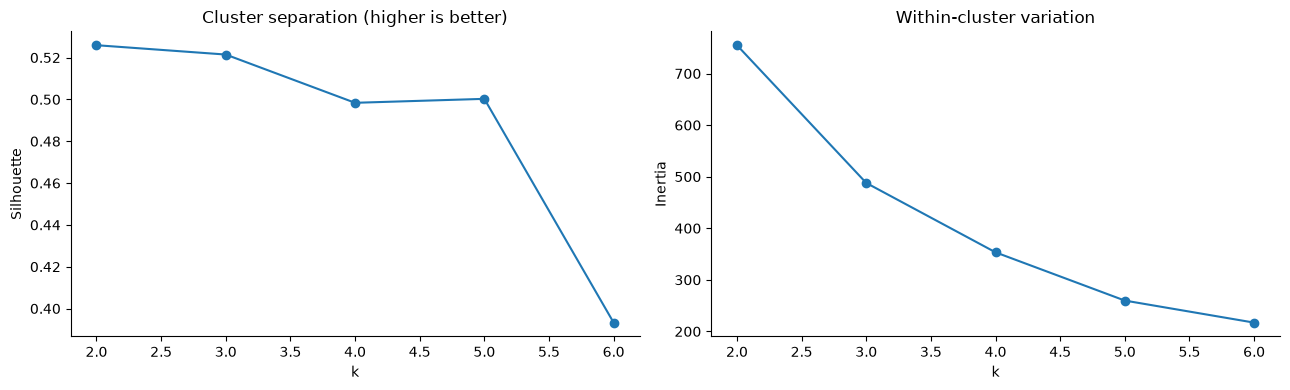

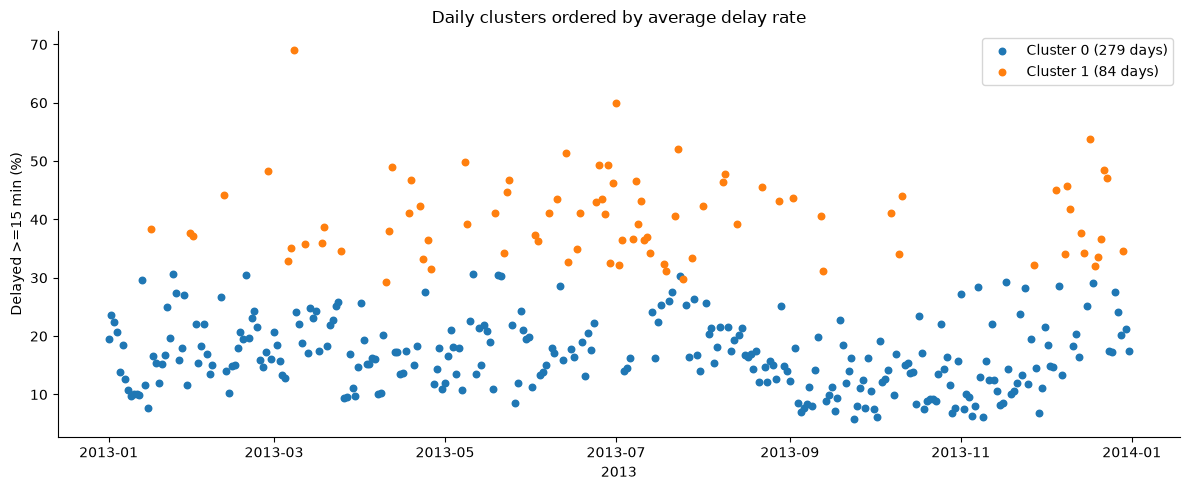

Selected k=2. Minimum seed agreement (adjusted Rand index): 1.000. Profiles report day-average rates, not flight-weighted rates. IDs increase with average delay rate; flight count also influences membership. Silhouette assesses geometry, not causal explanations or forecast accuracy.

In [3]:
labels, selection, stability, scaler, model, cluster_order = cluster_days(daily)
daily['cluster'] = labels.reindex(daily.index)
profile = daily.loc[daily.eligible].groupby('cluster').agg(
    days=('flights', 'size'), flights_mean=('flights', 'mean'),
    delay_rate_mean=('delay_rate', 'mean'), median_delay_mean=('median_delay', 'mean'),
    p90_delay_mean=('p90_delay', 'mean'), missing_rate_mean=('missing_rate', 'mean'))
selection.to_csv(TABLES / 'cluster_selection.csv')
stability.to_csv(TABLES / 'cluster_stability.csv', index=False)
profile.to_csv(TABLES / 'cluster_profiles.csv')
display(selection.round(3))
display(profile.round(3))
display(stability.round(3))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(selection.index, selection.silhouette, marker='o')
axes[0].set(title='Cluster separation (higher is better)', xlabel='k', ylabel='Silhouette')
axes[1].plot(selection.index, selection.inertia, marker='o')
axes[1].set(title='Within-cluster variation', xlabel='k', ylabel='Inertia')
save('cluster_selection')
fig, ax = plt.subplots(figsize=(12, 5))
for label, group in daily.dropna(subset=['cluster']).groupby('cluster'):
    ax.scatter(group.index, group.delay_rate * 100, s=22, label=f'Cluster {int(label)} ({len(group)} days)')
ax.set(title='Daily clusters ordered by average delay rate', xlabel='2013', ylabel='Delayed >=15 min (%)')
ax.legend()
save('cluster_timeline')
cluster_text = f'Selected k={model.n_clusters}. Minimum seed agreement (adjusted Rand index): {stability.adjusted_rand_index.min():.3f}. Profiles report day-average rates, not flight-weighted rates. IDs increase with average delay rate; flight count also influences membership. Silhouette assesses geometry, not causal explanations or forecast accuracy.'
display(Markdown(cluster_text))

,window_days,minimum_days,multiplier,scorable_days,delay_flags,missing_flags,common_days,primary_flags_on_common_days,alternative_flags_on_common_days
0,28,21,2.0,342,29,21,342,29,29
1,28,21,3.0,342,6,13,342,29,6
2,56,42,2.0,321,21,17,321,26,21


,delay_rate,delay_rate_baseline,delay_rate_threshold,delay_excess_pp,observed_labels,missing_rate,cluster
date,,,,,,,
2013-03-08,0.691,0.217,0.407,28.339,799,0.184,1
2013-12-05,0.450,0.159,0.302,14.779,811,0.163,1
2013-10-07,0.411,0.139,0.293,11.834,927,0.067,1
2013-10-11,0.440,0.146,0.317,12.359,936,0.055,1
2013-02-27,0.483,0.211,0.376,10.777,904,0.043,1
2013-04-12,0.489,0.205,0.381,10.849,916,0.074,1
2013-12-09,0.457,0.179,0.366,9.069,906,0.058,1
2013-02-11,0.443,0.205,0.374,6.876,856,0.079,1
2013-12-17,0.539,0.223,0.448,9.054,839,0.116,1


,missing_rate,missing_rate_baseline,missing_rate_threshold,flights,observed_labels
date,,,,,
2013-02-08,0.508,0.022,0.075,930,458
2013-05-23,0.224,0.012,0.052,988,767
2013-09-12,0.194,0.012,0.052,992,800
2013-12-05,0.163,0.007,0.047,969,811
2013-12-10,0.216,0.019,0.088,943,739
2013-02-09,0.575,0.040,0.231,684,291
2013-01-30,0.109,0.013,0.053,900,802
2013-04-10,0.103,0.011,0.051,989,887


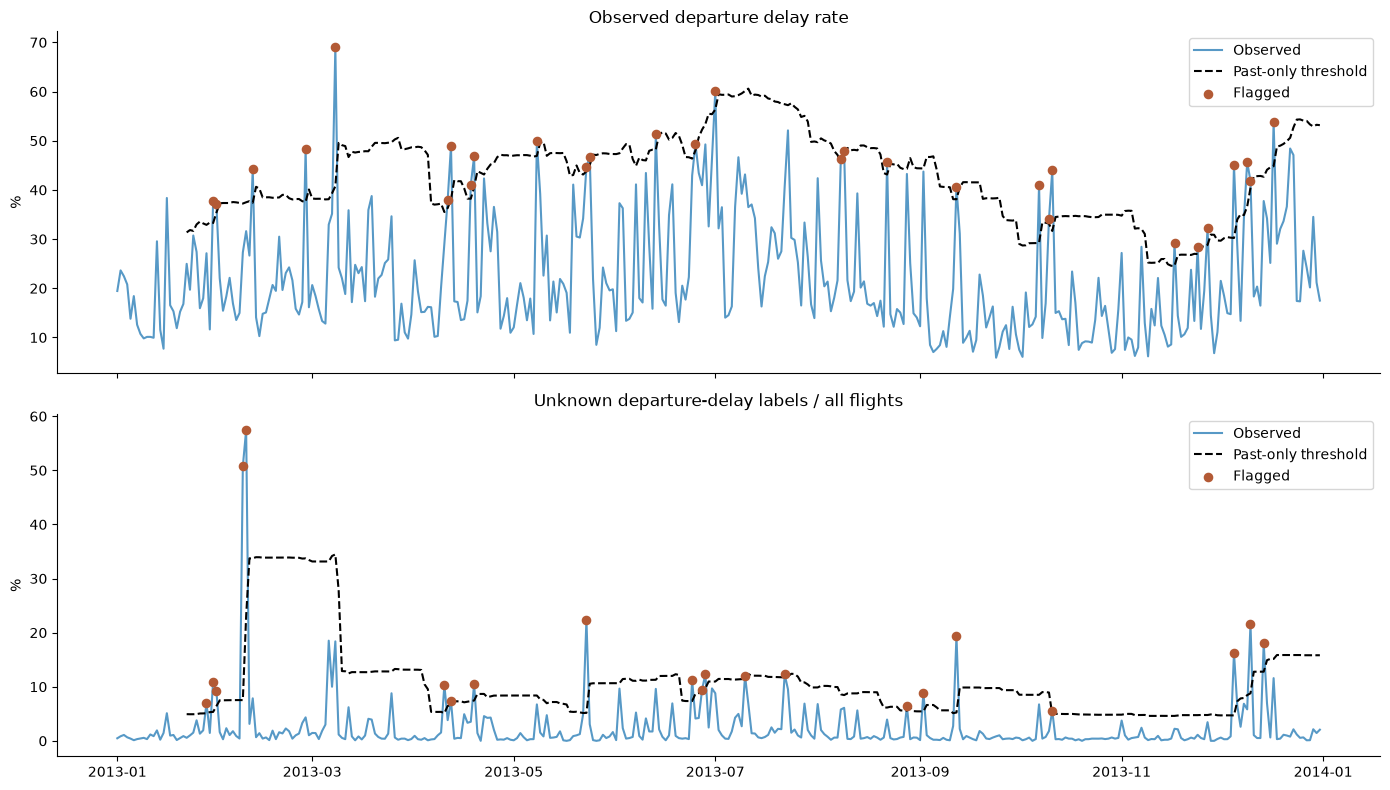

29 delay flags across 342 scorable days; 21 separate missing-label flags. Early dates without adequate history remain unscored. Threshold scores are descriptive deviations, not statistical significance tests. High absolute delays can be unflagged during an already disrupted period.

In [4]:
flags = historical_flags(daily)
result = daily.join(flags)
result['delay_excess_pp'] = (result.delay_rate - result.delay_rate_threshold) * 100
sensitivity_rows = []
for window, minimum, multiplier in [(28, 21, 2.), (28, 21, 3.), (56, 42, 2.)]:
    alternative = historical_flags(daily, window=window, min_periods=minimum, multiplier=multiplier)
    common = flags.delay_rate_flag.notna() & alternative.delay_rate_flag.notna()
    sensitivity_rows.append({'window_days': window, 'minimum_days': minimum, 'multiplier': multiplier,
        'scorable_days': int(alternative.delay_rate_flag.notna().sum()),
        'delay_flags': int(alternative.delay_rate_flag.sum()),
        'missing_flags': int(alternative.missing_rate_flag.sum()),
        'common_days': int(common.sum()),
        'primary_flags_on_common_days': int(flags.loc[common, 'delay_rate_flag'].sum()),
        'alternative_flags_on_common_days': int(alternative.loc[common, 'delay_rate_flag'].sum())})
sensitivity = pd.DataFrame(sensitivity_rows)
sensitivity.to_csv(TABLES / 'anomaly_sensitivity.csv', index=False)
delay_events = result.loc[result.delay_rate_flag.fillna(False)].sort_values('delay_rate_score', ascending=False)
missing_events = result.loc[result.missing_rate_flag.fillna(False)].sort_values('missing_rate_score', ascending=False)
delay_events.to_csv(TABLES / 'delay_anomalies.csv')
missing_events.to_csv(TABLES / 'missing_label_anomalies.csv')
display(sensitivity)
display(delay_events[['delay_rate', 'delay_rate_baseline', 'delay_rate_threshold', 'delay_excess_pp', 'observed_labels', 'missing_rate', 'cluster']].head(12).round(3))
display(missing_events[['missing_rate', 'missing_rate_baseline', 'missing_rate_threshold', 'flights', 'observed_labels']].head(8).round(3))
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
for ax, metric, title in zip(axes, ['delay_rate', 'missing_rate'], ['Observed departure delay rate', 'Unknown departure-delay labels / all flights']):
    ax.plot(result.index, result[metric] * 100, label='Observed', alpha=.75)
    ax.plot(result.index, result[f'{metric}_threshold'] * 100, label='Past-only threshold', color='black', linestyle='--')
    marked = result[f'{metric}_flag'].fillna(False)
    ax.scatter(result.index[marked], result.loc[marked, metric] * 100, color='#b35a35', s=35, label='Flagged', zorder=3)
    ax.set(title=title, ylabel='%')
    ax.legend()
save('historical_anomalies')
anomaly_text = f'{len(delay_events)} delay flags across {result.delay_rate_flag.notna().sum()} scorable days; {len(missing_events)} separate missing-label flags. Early dates without adequate history remain unscored. Threshold scores are descriptive deviations, not statistical significance tests. High absolute delays can be unflagged during an already disrupted period.'
display(Markdown(anomaly_text))

In [5]:
# Compare relative unusualness with cluster membership and previously investigated dates.
overlap = result.dropna(subset=['cluster']).groupby('cluster').agg(
    days=('flights', 'size'), scorable_days=('delay_rate_flag', 'count'),
    delay_flags=('delay_rate_flag', 'sum'), missing_flags=('missing_rate_flag', 'sum'))
overlap.to_csv(TABLES / 'cluster_anomaly_overlap.csv')
display(overlap)
case_dates = pd.to_datetime(['2013-03-08', '2013-07-01', '2013-07-23', '2013-02-09'])
cases = result.loc[case_dates, ['eligible', 'cluster', 'delay_rate', 'missing_rate', 'delay_rate_threshold', 'delay_rate_flag', 'missing_rate_flag']]
cases.to_csv(TABLES / 'pattern_case_studies.csv')
display(cases.round(3))
result.to_csv(TABLES / 'daily_patterns.csv')
joblib.dump({'scaler': scaler, 'kmeans': model, 'ordered_cluster_ids': cluster_order, 'features': FEATURES}, MODELS / 'daily_clusters.joblib')
config = {'source_sha256': hashlib.sha256(source.read_bytes()).hexdigest(), 'features': FEATURES,
    'selected_k': int(model.n_clusters), 'random_state': 42, 'n_init': 20, 'minimum_cluster_days': 10,
    'minimum_observed_labels': 500, 'minimum_label_coverage': .5,
    'baseline_window_days': 28, 'baseline_minimum_days': 21, 'threshold_multiplier': 2,
    'standard_deviation_floor': .02, 'sklearn_version': sklearn.__version__, 'fit_scope': 'full-year descriptive'}
(MODELS / 'daily_patterns_config.json').write_text(json.dumps(config, indent=2) + chr(10), encoding='utf-8')
report = chr(10).join(['# Daily clustering and anomaly findings', '', cluster_text, '',
    '## Cluster profiles (day-average statistics)', profile.to_string(), '',
    '## Past-only anomaly baseline', anomaly_text, '',
    'Threshold: previous 28 calendar-day mean + 2 * max(previous standard deviation, 0.02), requiring 21 prior valid days. Delay scoring requires >=500 labels and >=50% coverage; missing-label scoring uses all days.', '',
    '## Sensitivity checks', sensitivity.to_string(index=False), '',
    '## Relationship between clusters and anomalies', overlap.to_string(), '',
    'Clusters describe absolute daily behaviour; anomaly flags describe deviation from recent history. They need not agree.', '',
    '## Previously investigated dates', cases.to_string(), '',
    '## Limitations and next step',
    'K-means imposes groups on continuous data and depends on scaling and chosen features. Seed agreement is not evidence of causal or temporal validity.',
    'The recent baseline can adapt upward during disruption and does not adjust for weekdays, routes, carriers or seasons. Flags are investigation prompts, not confirmed events.',
    'Missing outcomes are not automatically cancellations. Warm-up/ineligible days are unknown, not normal.',
    'Full-year descriptive outcomes are not pre-departure prediction features. Next: chronological flight-delay classification using the existing train/validation/test partitions. Weather remains excluded.']) + chr(10)
(ROOT / 'reports/daily_patterns_findings.md').write_text(report, encoding='utf-8')
print('Saved daily assignments, profiles, sensitivity checks, case studies, figures, model and findings.')

,days,scorable_days,delay_flags,missing_flags
cluster,,,,
0,279,259,2,1
1,84,83,27,18


,eligible,cluster,delay_rate,missing_rate,delay_rate_threshold,delay_rate_flag,missing_rate_flag
2013-03-08,True,1,0.691,0.184,0.407,True,False
2013-07-01,True,1,0.600,0.088,0.563,True,False
2013-07-23,True,1,0.521,0.095,0.572,False,False
2013-02-09,False,<NA>,0.316,0.575,0.375,<NA>,True


Saved daily assignments, profiles, sensitivity checks, case studies, figures, model and findings.


In [6]:
# Check the historical baseline cannot see the current day or future dates.
from src.patterns import historical_flags
synthetic = pd.DataFrame({'delay_rate': .1, 'missing_rate': .01, 'eligible': True},
    index=pd.date_range('2013-01-01', periods=80, name='date'))
before = historical_flags(synthetic)
synthetic.loc[synthetic.index[40]:, 'delay_rate'] = .9
after = historical_flags(synthetic)
pd.testing.assert_series_equal(before.delay_rate_threshold.iloc[:41], after.delay_rate_threshold.iloc[:41])
assert before.delay_rate_flag.iloc[:21].isna().all()
assert after.delay_rate_flag.iloc[40]
assert before.delay_rate_flag.iloc[21:].eq(False).all()
assert labels.notna().sum() == daily.eligible.sum()
assert int(profile.days.sum()) == int(daily.eligible.sum())
assert result.loc[~result.eligible, 'delay_rate_flag'].isna().all()
assert ((result.delay_rate_flag.fillna(False)) <= (result.delay_rate > result.delay_rate_threshold)).all()
print('Passed: no look-ahead, warm-up handling, synthetic spike, cluster coverage and threshold consistency.')

Passed: no look-ahead, warm-up handling, synthetic spike, cluster coverage and threshold consistency.


In [7]:
# Interpret profiles and disagreements rather than treating IDs as explanations.
conclusions = ['## What these results tell us', '']
for cluster, row in profile.iterrows():
    conclusions.append(f'Cluster {int(cluster)} contains {int(row.days)} days: average daily delay rate {row.delay_rate_mean:.1%}, average daily median delay {row.median_delay_mean:.1f} minutes, and average daily 90th-percentile delay {row.p90_delay_mean:.1f} minutes.')
conclusions += [
    f'Two and three clusters have similar silhouette scores ({selection.loc[2, "silhouette"]:.3f} and {selection.loc[3, "silhouette"]:.3f}). The selected partition is a useful coarse summary, not evidence of two natural types of day.',
    f'{int(overlap.delay_flags.sum())} scorable delay spikes overlap the clusters; {int(overlap.loc[overlap.index.max(), "delay_flags"])} occur in the highest-delay cluster.',
    'March 8 and July 1 are both high-delay cluster members and past-baseline delay flags. July 23 is a high-delay cluster member but not a delay flag: its threshold has risen after preceding disruptions.',
    'February 8 and 9 have too few known departure delays for delay clustering/scoring, but both remain visible through the separate missing-label investigation. Unknown delay flags must not be interpreted as evidence that these days were normal.',
    f'The primary threshold flags {int(sensitivity.iloc[0].delay_flags)} days; using three standard deviations flags {int(sensitivity.iloc[1].delay_flags)}. Flag counts are threshold-sensitive, and the longer-window comparison also has a longer warm-up.',
    'For a dashboard, show cluster profile, raw rate, baseline, missing-label share and scoring status together. A single red/green normality label would hide important distinctions.',
    'Next, evaluate pre-departure flight classification chronologically. Do not feed these same-day, full-year outcome summaries into those models.',
]
conclusion_text = chr(10).join(conclusions) + chr(10)
display(Markdown(conclusion_text))
report_path = ROOT / 'reports/daily_patterns_findings.md'
report_path.write_text(report_path.read_text(encoding='utf-8') + chr(10) + conclusion_text, encoding='utf-8')

## What these results tell us

Cluster 0 contains 279 days: average daily delay rate 16.7%, average daily median delay -2.2 minutes, and average daily 90th-percentile delay 30.2 minutes.
Cluster 1 contains 84 days: average daily delay rate 40.4%, average daily median delay 6.2 minutes, and average daily 90th-percentile delay 107.7 minutes.
Two and three clusters have similar silhouette scores (0.526 and 0.521). The selected partition is a useful coarse summary, not evidence of two natural types of day.
29 scorable delay spikes overlap the clusters; 27 occur in the highest-delay cluster.
March 8 and July 1 are both high-delay cluster members and past-baseline delay flags. July 23 is a high-delay cluster member but not a delay flag: its threshold has risen after preceding disruptions.
February 8 and 9 have too few known departure delays for delay clustering/scoring, but both remain visible through the separate missing-label investigation. Unknown delay flags must not be interpreted as evidence that these days were normal.
The primary threshold flags 29 days; using three standard deviations flags 6. Flag counts are threshold-sensitive, and the longer-window comparison also has a longer warm-up.
For a dashboard, show cluster profile, raw rate, baseline, missing-label share and scoring status together. A single red/green normality label would hide important distinctions.
Next, evaluate pre-departure flight classification chronologically. Do not feed these same-day, full-year outcome summaries into those models.


5141